In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import matplotlib.colors as mcolors

In [14]:
def plot_teleconnection_robustness(
    field,
    lon, lat,
    snr_model=None,
    snr_obs=None,
    pval_model=None,
    snr_threshold=1.5,
    pval_threshold=0.05,
    use_pval=False,
    cmap='RdBu_r',
    vmin=None,
    vmax=None,
    title_main='',
    title_suffix='',
    cbar_label='',
):
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import Patch

    xx, yy = np.meshgrid(lon, lat)

    # --- Robustness masks ---
    if use_pval:
        mask_model = pval_model <= pval_threshold
        mask_obs   = snr_obs > snr_threshold if snr_obs is not None else None
    else:
        mask_model = snr_model > snr_threshold
        mask_obs   = snr_obs   > snr_threshold

    mask_both = mask_model & mask_obs if mask_obs is not None else mask_model

    # --- Figure ---
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    # ===========================
    # Panel A: signal field
    # ===========================
    im = axes[0].pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    # Colorbar via inset_axes
    cax = inset_axes(axes[0], width='70%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # Stippling
    axes[0].scatter(
        xx[mask_both.values], yy[mask_both.values],
        s=2, color='k', marker='.',
        transform=ccrs.PlateCarree(), zorder=5
    )
    axes[0].set_title(title_main)
    plot_background(axes[0])

    # ===========================
    # Panel B: categorical map
    # ===========================
    if mask_obs is not None:
        base       = np.where(~mask_model.values & ~mask_obs.values, 1, np.nan)
        model_only = np.where( mask_model.values & ~mask_obs.values, 1, np.nan)
        obs_only   = np.where(~mask_model.values &  mask_obs.values, 1, np.nan)
        both       = np.where( mask_both.values,                     1, np.nan)

        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, model_only,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, obs_only,
                           cmap=mcolors.ListedColormap(['tab:orange']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, both,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, both,
                           cmap=mcolors.ListedColormap(['tab:orange']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        # Both — single solid color
        both_color = '#7B4F9E'  # clear purple
        axes[1].pcolormesh(xx, yy, both,
                   cmap=mcolors.ListedColormap([both_color]),
                   vmin=0, vmax=1, alpha=0.8,
                   transform=ccrs.PlateCarree())
                   # Update legend
        legend_elements = [
            Patch(facecolor='lightgrey',               label='Neither'),
            Patch(facecolor='tab:blue',   alpha=0.6,   label='Model only'),
            Patch(facecolor='tab:orange', alpha=0.6,   label='Obs only'),
            Patch(facecolor='#7B4F9E',    alpha=0.8,   label='Both'),
        ]
    else:
        base   = np.where(~mask_both.values, 1, np.nan)
        robust = np.where( mask_both.values, 1, np.nan)

        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, robust,
                           cmap=mcolors.ListedColormap(['tab:red']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())

        legend_elements = [
            Patch(facecolor='lightgrey',           label='Not robust'),
            Patch(facecolor='tab:red', alpha=0.6,  label='Robust'),
        ]

    axes[1].legend(handles=legend_elements, loc='lower left',
                   fontsize=8, framealpha=0.9)
    axes[1].set_title(title_suffix)
    plot_background(axes[1])

    plt.tight_layout()
    # return fig

In [15]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Patch

def plot_composite(field, lon, lat, vmin=-1.0, vmax=1.0,
                   cmap='RdBu_r', cbar_label='', title=''):
    
    xx, yy = np.meshgrid(lon, lat)
    
    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )
    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)
    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig


def plot_baseline_teleconnection(
    field,
    lon, lat,
    sig_data,
    mode='cmip6',
    p_threshold=0.05,
    agreement_threshold=0.8,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='',
    title='',
):
    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # --- Agreement / significance ---
    sig = sig_data <= p_threshold
    if mode == 'cmip6':
        agreement = sig.mean('model')
    elif mode == 'smile':
        sig_stacked = sig.stack(ensemble=('model', 'smile'))
        agreement   = sig_stacked.mean('ensemble')
    else:
        raise ValueError("mode must be 'cmip6' or 'smile'")

    mask = agreement >= agreement_threshold
    ax.scatter(
        xx[mask.values], yy[mask.values],
        s=1, marker='.', color='k',
        transform=ccrs.PlateCarree(), zorder=5
    )

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig

In [16]:
import sys

In [17]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [18]:
from functions import preproc_funcs as funcs

In [19]:
base_path = '/g/data/if69/as8561/data/enso_tele_robustness'

# Load all three scenarios
ts_ssp5 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc")
ts_ssp2 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp2.nc")
ts_ssp1 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp1.nc")
print('Done')

pr_ssp5 = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc")
pr_ssp2 = xr.open_dataset(f"{base_path}/cmip6/pr_ssp2.nc")
pr_ssp1 = xr.open_dataset(f"{base_path}/cmip6/pr_ssp1.nc")
print('Done')


Done
Done


In [20]:
common_models = sorted(list(
    set(ts_ssp5.model.values) &
    set(ts_ssp2.model.values) &
    set(ts_ssp1.model.values)
))

# Subset using isin instead
# ts_ssp5 = ts_ssp5.isel(model=ts_ssp5.model.isin(common_models))
ts_ssp2 = ts_ssp2.isel(model=ts_ssp2.model.isin(common_models))
ts_ssp1 = ts_ssp1.isel(model=ts_ssp1.model.isin(common_models))

# pr_ssp5 = pr_ssp5.isel(model=pr_ssp5.model.isin(common_models))
pr_ssp2 = pr_ssp2.isel(model=pr_ssp2.model.isin(common_models))
pr_ssp1 = pr_ssp1.isel(model=pr_ssp1.model.isin(common_models))

print(f"SSP585: {len(ts_ssp5.model)} models")
print(f"SSP245: {len(ts_ssp2.model)} models")
print(f"SSP126: {len(ts_ssp1.model)} models")

SSP585: 47 models
SSP245: 41 models
SSP126: 41 models


In [21]:
import xesmf as xe

In [22]:
# Load one SMILE just for grid template
smile_template = xr.open_dataset(f"{base_path}/smiles/ACCESS-ESM1-5_ts.nc", 
                                  decode_times=False)
smile_template = xr.decode_cf(smile_template).convert_calendar('standard', use_cftime=False)

# Build regridder
regridder_cmip6_to_smile = xe.Regridder(
    ts_ssp5, smile_template,
    'bilinear', periodic=True, ignore_degenerate=True
)

# Regrid all scenarios
ts_ssp5_regrid = regridder_cmip6_to_smile(ts_ssp5['ts'])
pr_ssp5_regrid = regridder_cmip6_to_smile(pr_ssp5['pr'])
ts_ssp2_regrid = regridder_cmip6_to_smile(ts_ssp2['ts'])
pr_ssp2_regrid = regridder_cmip6_to_smile(pr_ssp2['pr'])
ts_ssp1_regrid = regridder_cmip6_to_smile(ts_ssp1['ts'])
pr_ssp1_regrid = regridder_cmip6_to_smile(pr_ssp1['pr'])

In [23]:
tas_obs = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_rean = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34  = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()

# Detrend
tas_obs['tas'] = funcs.detrend_rolling_window(tas_obs['tas'], window_size=15)
pr_rean['pr']  = funcs.detrend_rolling_window(pr_rean['pr'],  window_size=15)
pr_rean['pr']  = pr_rean['pr'] / pr_rean['pr'].std('time')

# Regrid to SMILE grid
regridder_tas_obs = xe.Regridder(tas_obs, smile_template, 'bilinear',
                                  periodic=True, ignore_degenerate=True)
regridder_pr_rean = xe.Regridder(pr_rean, smile_template, 'bilinear',
                                  periodic=True, ignore_degenerate=True)
tas_obs_regrid = regridder_tas_obs(tas_obs['tas'])
pr_rean_regrid = regridder_pr_rean(pr_rean['pr'])

# Obs ENSO masks
nino34_obs       = nino34.rename({'tos': 'ts'})
nino34_obs['ts'] = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)
obs_std          = float(nino34_obs['ts'].sel(time=clim_base_slice).std('time'))
cond_en_obs      = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs      = nino34_obs['ts'] < -0.5 * obs_std

NameError: name 'clim_base_slice' is not defined

In [ ]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

In [ ]:
clim_fut = slice('2070', '2100')

def make_composites_scenario(ts_regrid, pr_regrid, cond_en, cond_ln):
    tas_en_base = ts_regrid.sel(time=clim_base_slice).where(cond_en.sel(time=clim_base_slice)).mean('time', skipna=True)
    tas_ln_base = ts_regrid.sel(time=clim_base_slice).where(cond_ln.sel(time=clim_base_slice)).mean('time', skipna=True)
    pr_en_base  = pr_regrid.sel(time=clim_base_slice).where(cond_en.sel(time=clim_base_slice)).mean('time', skipna=True)
    pr_ln_base  = pr_regrid.sel(time=clim_base_slice).where(cond_ln.sel(time=clim_base_slice)).mean('time', skipna=True)

    tas_en_fut  = ts_regrid.sel(time=clim_fut).where(cond_en.sel(time=clim_fut)).mean('time', skipna=True)
    tas_ln_fut  = ts_regrid.sel(time=clim_fut).where(cond_ln.sel(time=clim_fut)).mean('time', skipna=True)
    pr_en_fut   = pr_regrid.sel(time=clim_fut).where(cond_en.sel(time=clim_fut)).mean('time', skipna=True)
    pr_ln_fut   = pr_regrid.sel(time=clim_fut).where(cond_ln.sel(time=clim_fut)).mean('time', skipna=True)

    return dict(
        tas_en_signal = (tas_en_fut - tas_en_base).mean('model'),
        tas_ln_signal = (tas_ln_fut - tas_ln_base).mean('model'),
        pr_en_signal  = (pr_en_fut  - pr_en_base).mean('model'),
        pr_ln_signal  = (pr_ln_fut  - pr_ln_base).mean('model'),
        tas_en_pval   = ttest_ind3d(tas_en_fut, tas_en_base, dim='model'),
        tas_ln_pval   = ttest_ind3d(tas_ln_fut, tas_ln_base, dim='model'),
        pr_en_pval    = ttest_ind3d(pr_en_fut,  pr_en_base,  dim='model'),
        pr_ln_pval    = ttest_ind3d(pr_ln_fut,  pr_ln_base,  dim='model'),
    )

ssp5_comp = make_composites_scenario(ts_ssp5_regrid, pr_ssp5_regrid, cond_en_ssp5, cond_ln_ssp5)
ssp2_comp = make_composites_scenario(ts_ssp2_regrid, pr_ssp2_regrid, cond_en_ssp2, cond_ln_ssp2)
ssp1_comp = make_composites_scenario(ts_ssp1_regrid, pr_ssp1_regrid, cond_en_ssp1, cond_ln_ssp1)

In [ ]:
# --- Obs rolling 30-year composite std as noise ---
def obs_rolling_std(da, cond_en, cond_ln,
                    start=1900, end=2014, duration=30, gap=1):
    en_means, ln_means = [], []
    for yr in range(start, end - duration + 2, gap):
        win    = slice(str(yr), str(yr + duration - 1))
        en_sub = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
        ln_sub = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
        if en_sub.sizes['time'] > 2:
            en_means.append(en_sub.mean('time', skipna=True))
        if ln_sub.sizes['time'] > 2:
            ln_means.append(ln_sub.mean('time', skipna=True))
    en_std = xr.concat(en_means, dim='window').std('window')
    ln_std = xr.concat(ln_means, dim='window').std('window')
    return en_std, ln_std

In [ ]:
print("Computing obs rolling std for TAS...")
noise_en_tas_obs, noise_ln_tas_obs = obs_rolling_std(tas_obs_regrid, cond_en_obs, cond_ln_obs)

print("Computing obs rolling std for PR...")
noise_en_pr_obs, noise_ln_pr_obs = obs_rolling_std(pr_rean_regrid, cond_en_obs, cond_ln_obs)

Computing obs rolling std for TAS...
Computing obs rolling std for PR...


In [ ]:
threshold = 1.5

for name, comp in [('ssp5', ssp5_comp), ('ssp2', ssp2_comp), ('ssp1', ssp1_comp)]:
    comp['tas_en_snr_obs'] = comp['tas_en_signal'] / noise_en_tas_obs
    comp['tas_ln_snr_obs'] = comp['tas_ln_signal'] / noise_ln_tas_obs
    comp['pr_en_snr_obs']  = comp['pr_en_signal']  / noise_en_pr_obs
    comp['pr_ln_snr_obs']  = comp['pr_ln_signal']  / noise_ln_pr_obs

    comp['tas_en_rob_ttest'] = comp['tas_en_pval'] < 0.05
    comp['tas_ln_rob_ttest'] = comp['tas_ln_pval'] < 0.05
    comp['pr_en_rob_ttest']  = comp['pr_en_pval']  < 0.05
    comp['pr_ln_rob_ttest']  = comp['pr_ln_pval']  < 0.05

    comp['tas_en_rob_obs'] = np.abs(comp['tas_en_snr_obs']) > threshold
    comp['tas_ln_rob_obs'] = np.abs(comp['tas_ln_snr_obs']) > threshold
    comp['pr_en_rob_obs']  = np.abs(comp['pr_en_snr_obs'])  > threshold
    comp['pr_ln_rob_obs']  = np.abs(comp['pr_ln_snr_obs'])  > threshold

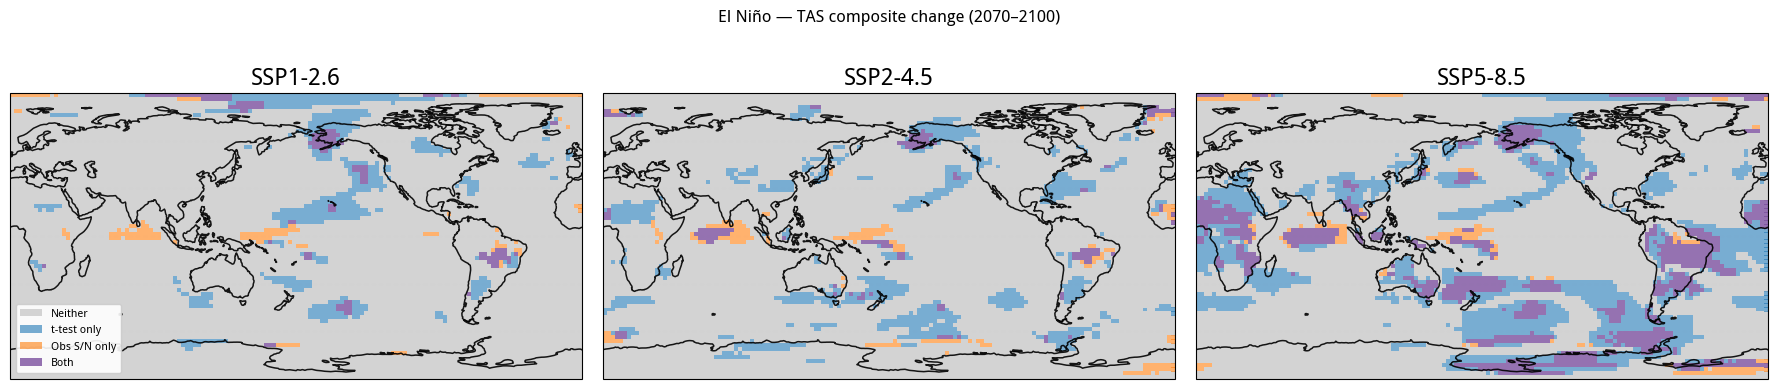

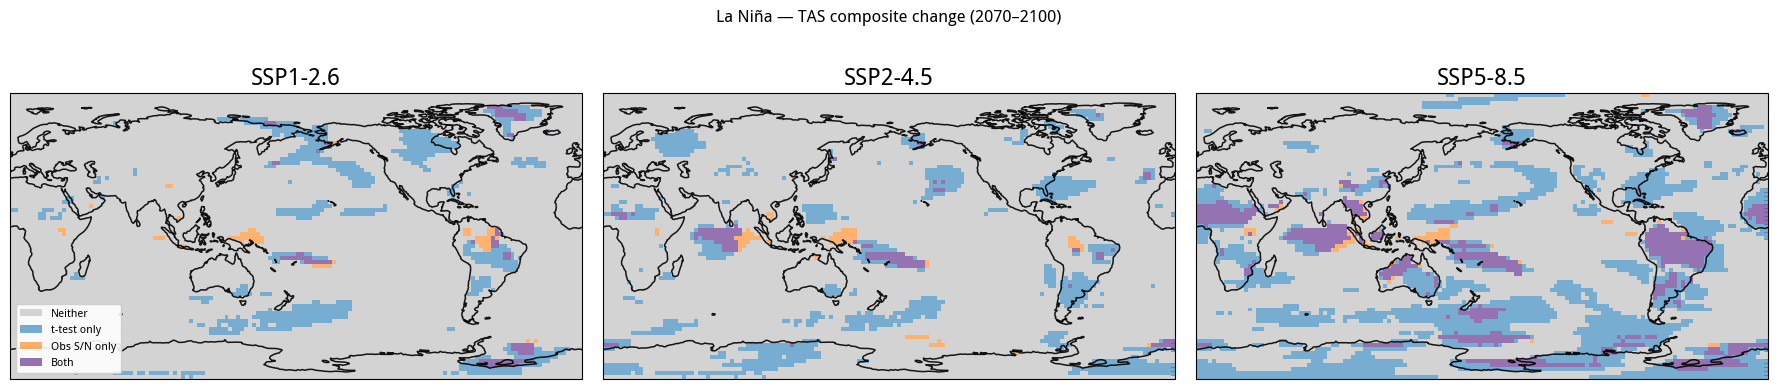

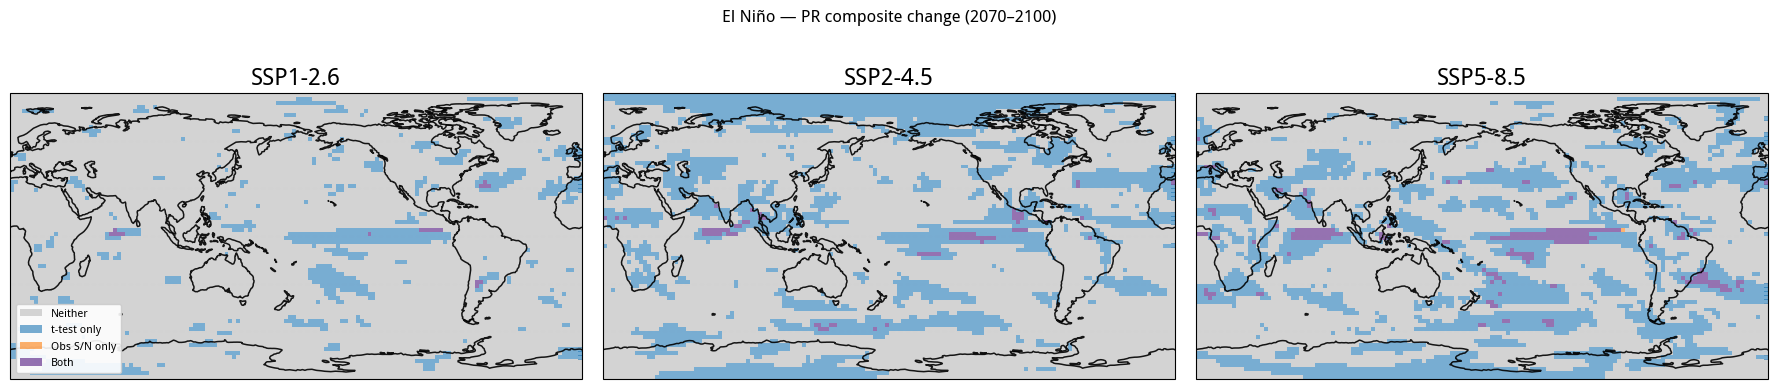

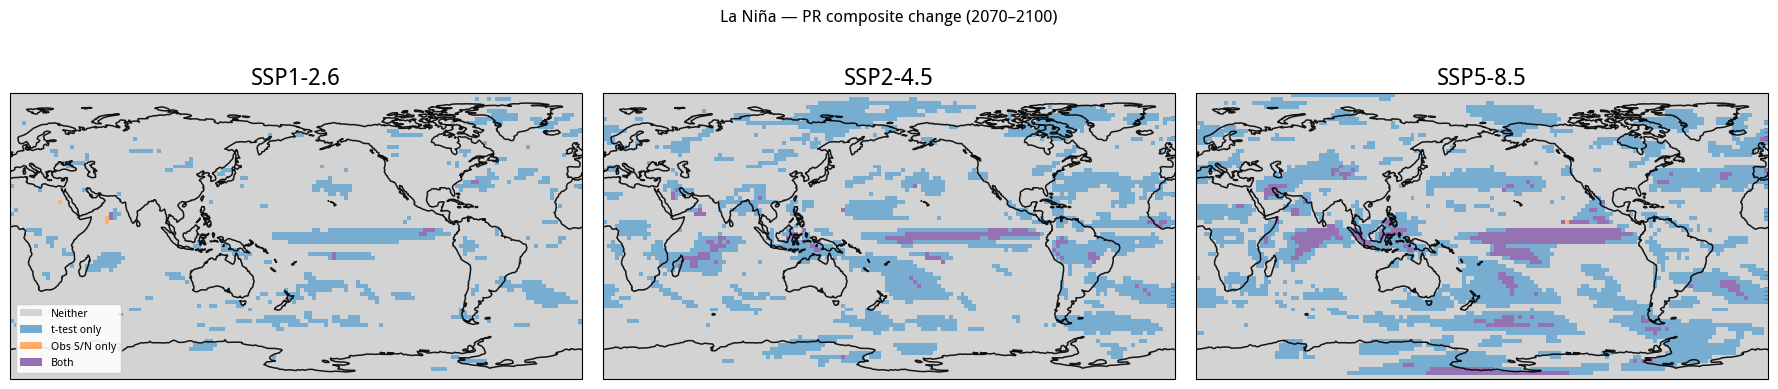

In [ ]:
lon = smile_template.lon.values
lat = smile_template.lat.values

for var, cmap, vmin, vmax, cbar_label in [
    ('tas', 'RdBu_r', -1.5, 1.5, 'TAS (°C)'),
    ('pr',  'BrBG',   -1.5, 1.5, 'PR (normalised)')
]:
    for phase, phase_label in [('en', 'El Niño'), ('ln', 'La Niña')]:

        fig, axes = plt.subplots(
            1, 3, figsize=(18, 4),
            subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
        )

        for ax, (name, comp, ssp_label) in zip(axes, [
            ('ssp1', ssp1_comp, 'SSP1-2.6'),
            ('ssp2', ssp2_comp, 'SSP2-4.5'),
            ('ssp5', ssp5_comp, 'SSP5-8.5'),
        ]):
            mask_ttest = comp[f'{var}_{phase}_rob_ttest']
            mask_obs   = comp[f'{var}_{phase}_rob_obs']
            mask_both  = mask_ttest & mask_obs

            base       = np.where(~mask_ttest.values & ~mask_obs.values, 1, np.nan)
            model_only = np.where( mask_ttest.values & ~mask_obs.values, 1, np.nan)
            obs_only   = np.where(~mask_ttest.values &  mask_obs.values, 1, np.nan)
            both       = np.where( mask_both.values,                     1, np.nan)

            xx, yy = np.meshgrid(lon, lat)

            ax.pcolormesh(xx, yy, base,
                          cmap=mcolors.ListedColormap(['lightgrey']),
                          vmin=0, vmax=1, transform=ccrs.PlateCarree())
            ax.pcolormesh(xx, yy, model_only,
                          cmap=mcolors.ListedColormap(['tab:blue']),
                          vmin=0, vmax=1, alpha=0.6, transform=ccrs.PlateCarree())
            ax.pcolormesh(xx, yy, obs_only,
                          cmap=mcolors.ListedColormap(['tab:orange']),
                          vmin=0, vmax=1, alpha=0.6, transform=ccrs.PlateCarree())
            ax.pcolormesh(xx, yy, both,
                          cmap=mcolors.ListedColormap(['#7B4F9E']),
                          vmin=0, vmax=1, alpha=0.8, transform=ccrs.PlateCarree())

            ax.set_title(ssp_label)
            plot_background(ax)

        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor='lightgrey',              label='Neither'),
            Patch(facecolor='tab:blue',   alpha=0.6,  label='t-test only'),
            Patch(facecolor='tab:orange', alpha=0.6,  label='Obs S/N only'),
            Patch(facecolor='#7B4F9E',    alpha=0.8,  label='Both'),
        ]
        axes[0].legend(handles=legend_elements, loc='lower left',
                       fontsize=8, framealpha=0.9)

        fig.suptitle(f'{phase_label} — {var.upper()} composite change (2070–2100)',
                     fontsize=12, y=1.02)
        plt.tight_layout()
        plt.show()